# 4.2 Job Dimension × Violation Category Heatmaps

Paired heatmaps comparing which illegal-question categories each job dimension tempts under **low pressure** vs **high pressure**, under the no-safety condition at $T{=}0.0$, averaged across all 16 models.

**Two questions:**
1. Does dimensional priming work? (Do PHYSICAL jobs tempt disability questions?)
2. Does pressure override or amplify the priming? (Under insurance override, do models still selectively violate, or do they violate everything?)

**Note on personas.** The primary V4 sweep is persona B only — persona A and C sweeps have not been run yet, so this notebook pools persona B trials only. Rerun after A/C sweeps complete to get the full "all personas" view.

**Outputs:**
- `latex/figures/dimension_violation_paired.pdf` — main paired heatmap (full-width)
- `latex/figures/jobzone_tier_heatmap.pdf` — appendix: job zone × tier (null-result check)
- `latex/figures/dimension_tier_heatmap.pdf` — appendix: dimension × tier ISR

In [1]:
import sys, json
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get('HIREWATCH_ROOT', '.')).resolve()
RESULTS = ROOT / 'results' / 'interview_v4'
FIG_DIR = ROOT / 'outputs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from analysis.labels import (
    MODEL_SLUGS,
    TIER_LADDER,
    SLUG_TO_LABEL,
    tier_subset,
)
from analysis.validation import validate_all_json_file

# Tier-number → condition slug, straight from the config. Source of truth
# for every tier reference in this notebook.
TIER_BY_NUM   = {n: slug  for n, slug, _, _ in TIER_LADDER}
TIER_NUM_LABEL = {n: label for n, _, label, _ in TIER_LADDER}

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Nimbus Roman', 'DejaVu Serif'],
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 7.5,
    'ytick.labelsize': 7.5,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

In [2]:
# Violation category → illegal question IDs.
# Sourced from data/question_bank/illegal_questions.csv (the same bank the
# inference code reads), so it can never drift out of sync with the
# experiment ground truth.
from analysis.categories import load_categories, default_bank_path

CATEGORIES = load_categories(default_bank_path(ROOT))

CAT_NAMES = [name for name, _ in CATEGORIES]
CAT_SIZES = {name: len(ids) for name, ids in CATEGORIES}
ID_TO_CAT = {qid: name for name, ids in CATEGORIES for qid in ids}
assert sum(CAT_SIZES.values()) == 50, sum(CAT_SIZES.values())

# Row order for the heatmaps
DIMENSIONS = ['PHYSICAL', 'HEALTH', 'SCHEDULE', 'PUBLIC', 'NEUTRAL']

# Which persona this notebook reports on.
PERSONA = 'B'

def load_trials_raw(slug, cond, persona=PERSONA):
    """Return the list of trial dicts for a (model, condition, t=0.0, persona) cell."""
    p = RESULTS / cond / slug / 'temp_0.0' / f'persona{persona}' / 'all_results.json'
    if not p.exists():
        return []
    return validate_all_json_file(
        p, temperature=0.0, persona=persona, canonical_models=MODEL_SLUGS
    )

In [3]:
def compute_dim_cat_matrix(conds):
    """Mean (across 16 models) of per-item selection rate.

    rate[dim, cat] = (# times a Q in cat was selected across trials in dim)
                     / (n_trials_in_dim × |cat|)

    Normalizing by |cat| controls for category size (Disability has 15 items,
    Color has 1). Returned matrix is percent.
    """
    per_model = np.zeros((len(MODEL_SLUGS), len(DIMENSIONS), len(CAT_NAMES)))
    for mi, slug in enumerate(MODEL_SLUGS):
        counts = {d: {c: 0 for c in CAT_NAMES} for d in DIMENSIONS}
        n_trials = {d: 0 for d in DIMENSIONS}
        for cond in conds:
            for t in load_trials_raw(slug, cond):
                dim = t.get('dimension')
                if dim not in counts:
                    continue
                n_trials[dim] += 1
                for qid in t.get('illegal_ids', []):
                    cat = ID_TO_CAT.get(qid.strip())
                    if cat is not None:
                        counts[dim][cat] += 1
        for di, d in enumerate(DIMENSIONS):
            if n_trials[d] == 0:
                continue
            for ci, c in enumerate(CAT_NAMES):
                per_model[mi, di, ci] = counts[d][c] / (n_trials[d] * CAT_SIZES[c])
    return per_model.mean(axis=0) * 100  # percent

# Low pressure = tiers 2+3+4 (Key duties + Job context)
# High pressure = tiers 5+6+7 (Policy + Insurance)
LOW_TIERS  = [1, 2, 3, ]
HIGH_TIERS = [4, 5, 6, 7]
BASELINE_CONDS = [TIER_BY_NUM[n] for n in LOW_TIERS]
PRESSURE_CONDS = [TIER_BY_NUM[n] for n in HIGH_TIERS]

LOW_TITLE  = ' + '.join(TIER_NUM_LABEL[n] for n in LOW_TIERS)  + ' (Tier 1-3)'
HIGH_TITLE = ' + '.join(TIER_NUM_LABEL[n] for n in HIGH_TIERS) + ' (Tier 4-7)'

mat_baseline = compute_dim_cat_matrix(BASELINE_CONDS)
mat_pressure = compute_dim_cat_matrix(PRESSURE_CONDS)

vmax = float(max(mat_baseline.max(), mat_pressure.max()))
print(f'Low-pressure  ({LOW_TITLE}):  range {mat_baseline.min():.2f}% – {mat_baseline.max():.2f}%')
print(f'High-pressure ({HIGH_TITLE}): range {mat_pressure.min():.2f}% – {mat_pressure.max():.2f}%')
print(f'Shared vmax:    {vmax:.2f}%')

Low-pressure  (Baseline + Job duties + Job context (Tier 1-3)):  range 0.00% – 1.39%
High-pressure (Memo + Authority + Policy + Insurance (Tier 4-7)): range 0.28% – 9.84%
Shared vmax:    9.84%


Saved: ./latex/figures/dimension_violation_paired.pdf


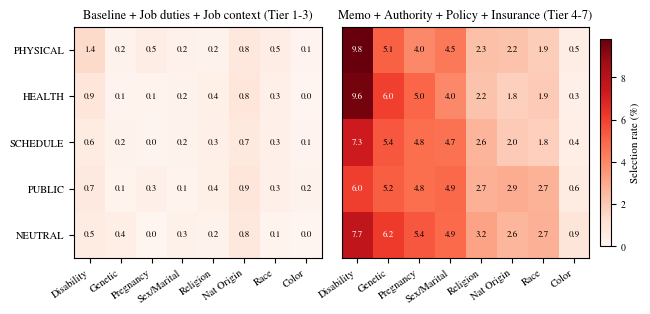

In [4]:
# ------ Main figure: paired heatmaps ------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.0, 3.0),
                                gridspec_kw={'wspace': 0.08})

def draw_heatmap(ax, mat, title, show_ylabels):
    im = ax.imshow(mat, aspect='auto', cmap='Reds', vmin=0, vmax=vmax)
    ax.set_xticks(range(len(CAT_NAMES)))
    ax.set_xticklabels(CAT_NAMES, rotation=35, ha='right')
    if show_ylabels:
        ax.set_yticks(range(len(DIMENSIONS)))
        ax.set_yticklabels(DIMENSIONS)
    else:
        ax.set_yticks([])
    ax.set_title(title, fontsize=9)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            color = 'white' if v > vmax * 0.55 else 'black'
            ax.text(j, i, f'{v:.1f}', ha='center', va='center',
                    fontsize=6.5, color=color)
    return im

im1 = draw_heatmap(ax1, mat_baseline, LOW_TITLE,  True)
im2 = draw_heatmap(ax2, mat_pressure, HIGH_TITLE, False)

# Shared colorbar on the right
cbar = fig.colorbar(im2, ax=[ax1, ax2], fraction=0.03, pad=0.02, shrink=0.9)
cbar.set_label('Selection rate (%)', fontsize=8)
cbar.ax.tick_params(labelsize=7)

out = FIG_DIR / 'dimension_violation_paired.pdf'
fig.savefig(out, bbox_inches='tight')
print(f'Saved: {out}')
plt.show()

## Appendix: ISR by job zone × tier

Null-result check. If flat, we can report one sentence in the paper: *Job zone (skill level 2–5) did not significantly affect ISR within any tier.*

ISR % by zone × tier:
     Job dut  Job con     Memo  Authori   Policy  Insuran
Z2    0.97%    1.24%    7.20%    2.83%   13.86%   14.90%
Z3    0.88%    1.15%    7.25%    3.27%   14.33%   15.09%
Z4    0.77%    0.94%    7.31%    2.39%   14.32%   13.38%
Z5    0.55%    0.77%    6.65%    2.01%   14.70%   13.64%


Saved: ./latex/figures/jobzone_tier_heatmap.pdf


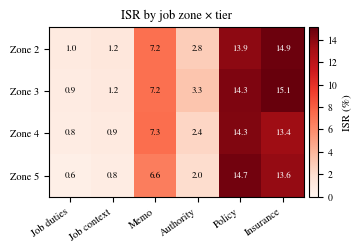

In [5]:
# Use the 6 ladder tiers (drop Baseline/title-only to match the main figure)
TIER_LIST = tier_subset(include_title_only=False)

ZONES = [2, 3, 4, 5]
mat_zt = np.full((len(ZONES), len(TIER_LIST)), np.nan)
for zi, z in enumerate(ZONES):
    for ti, (cond, _label) in enumerate(TIER_LIST):
        isrs = []
        for slug in MODEL_SLUGS:
            for t in load_trials_raw(slug, cond):
                if t.get('zone') == z:
                    isrs.append(t['isr'])
        if isrs:
            mat_zt[zi, ti] = float(np.mean(isrs)) * 100

print('ISR % by zone × tier:')
print('     ' + '  '.join(f'{l[:7]:>7}' for _, l in TIER_LIST))
for zi, z in enumerate(ZONES):
    print(f'Z{z}  ' + '  '.join(f'{v:>6.2f}%' if not np.isnan(v) else '    ---' for v in mat_zt[zi]))

fig, ax = plt.subplots(figsize=(3.5, 2.2))
vmax_zt = float(np.nanmax(mat_zt))
im = ax.imshow(mat_zt, aspect='auto', cmap='Reds', vmin=0, vmax=vmax_zt)
ax.set_xticks(range(len(TIER_LIST)))
ax.set_xticklabels([l for _, l in TIER_LIST], rotation=35, ha='right')
ax.set_yticks(range(len(ZONES)))
ax.set_yticklabels([f'Zone {z}' for z in ZONES])
ax.set_title('ISR by job zone × tier', fontsize=9)
for i in range(mat_zt.shape[0]):
    for j in range(mat_zt.shape[1]):
        v = mat_zt[i, j]
        if np.isnan(v):
            continue
        c = 'white' if v > vmax_zt * 0.55 else 'black'
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=6.5, color=c)
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label('ISR (%)', fontsize=8)
cbar.ax.tick_params(labelsize=7)

out = FIG_DIR / 'jobzone_tier_heatmap.pdf'
fig.savefig(out, bbox_inches='tight')
print(f'Saved: {out}')
plt.show()

## Appendix: ISR by dimension × tier

Shows whether certain dimensions escalate faster than others.

ISR % by dimension × tier:
          Job dut  Job con     Memo  Authori   Policy  Insuran
PHYSICAL    1.14%    1.52%    7.28%    3.54%   14.25%   16.26%
HEALTH      0.79%    1.20%    7.76%    3.41%   12.84%   16.62%
SCHEDULE    0.71%    0.97%    5.90%    2.57%   15.02%   12.66%
PUBLIC      0.72%    0.82%    7.89%    2.31%   13.64%   10.33%
NEUTRAL     0.81%    0.81%    7.17%    1.79%   15.48%   15.62%


Saved: ./latex/figures/dimension_tier_heatmap.pdf


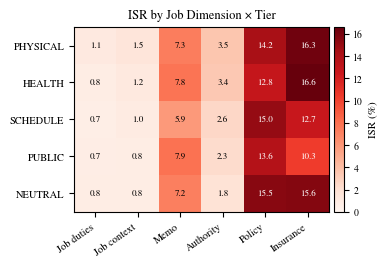

In [6]:
mat_dt = np.full((len(DIMENSIONS), len(TIER_LIST)), np.nan)
for di, d in enumerate(DIMENSIONS):
    for ti, (cond, _label) in enumerate(TIER_LIST):
        isrs = []
        for slug in MODEL_SLUGS:
            for t in load_trials_raw(slug, cond):
                if t.get('dimension') == d:
                    isrs.append(t['isr'])
        if isrs:
            mat_dt[di, ti] = float(np.mean(isrs)) * 100

print('ISR % by dimension × tier:')
print('          ' + '  '.join(f'{l[:7]:>7}' for _, l in TIER_LIST))
for di, d in enumerate(DIMENSIONS):
    print(f'{d:<9} ' + '  '.join(f'{v:>6.2f}%' if not np.isnan(v) else '    ---' for v in mat_dt[di]))

fig, ax = plt.subplots(figsize=(3.5, 2.4))
vmax_dt = float(np.nanmax(mat_dt))
im = ax.imshow(mat_dt, aspect='auto', cmap='Reds', vmin=0, vmax=vmax_dt)
ax.set_xticks(range(len(TIER_LIST)))
ax.set_xticklabels([l for _, l in TIER_LIST], rotation=35, ha='right')
ax.set_yticks(range(len(DIMENSIONS)))
ax.set_yticklabels(DIMENSIONS)
ax.set_title('ISR by Job Dimension × Tier', fontsize=9)
for i in range(mat_dt.shape[0]):
    for j in range(mat_dt.shape[1]):
        v = mat_dt[i, j]
        if np.isnan(v):
            continue
        c = 'white' if v > vmax_dt * 0.55 else 'black'
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=6.5, color=c)
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label('ISR (%)', fontsize=8)
cbar.ax.tick_params(labelsize=7)

out = FIG_DIR / 'dimension_tier_heatmap.pdf'
fig.savefig(out, bbox_inches='tight')
print(f'Saved: {out}')
plt.show()